# Traffic Behavior Dataset

Dataset describes the urban traffic in the city São Paulo from December 14, 2009 to December 18, 2009 — from Monday to Friday.

Researchers Ricardo Pinto Ferreira, Andréa Martiniano, and Renato Jose Sassi collected the dataset. Dataset can be dowloaded from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/datasets/Behavior+of+the+urban+traffic+of+the+city+of+Sao+Paulo+in+Brazil)

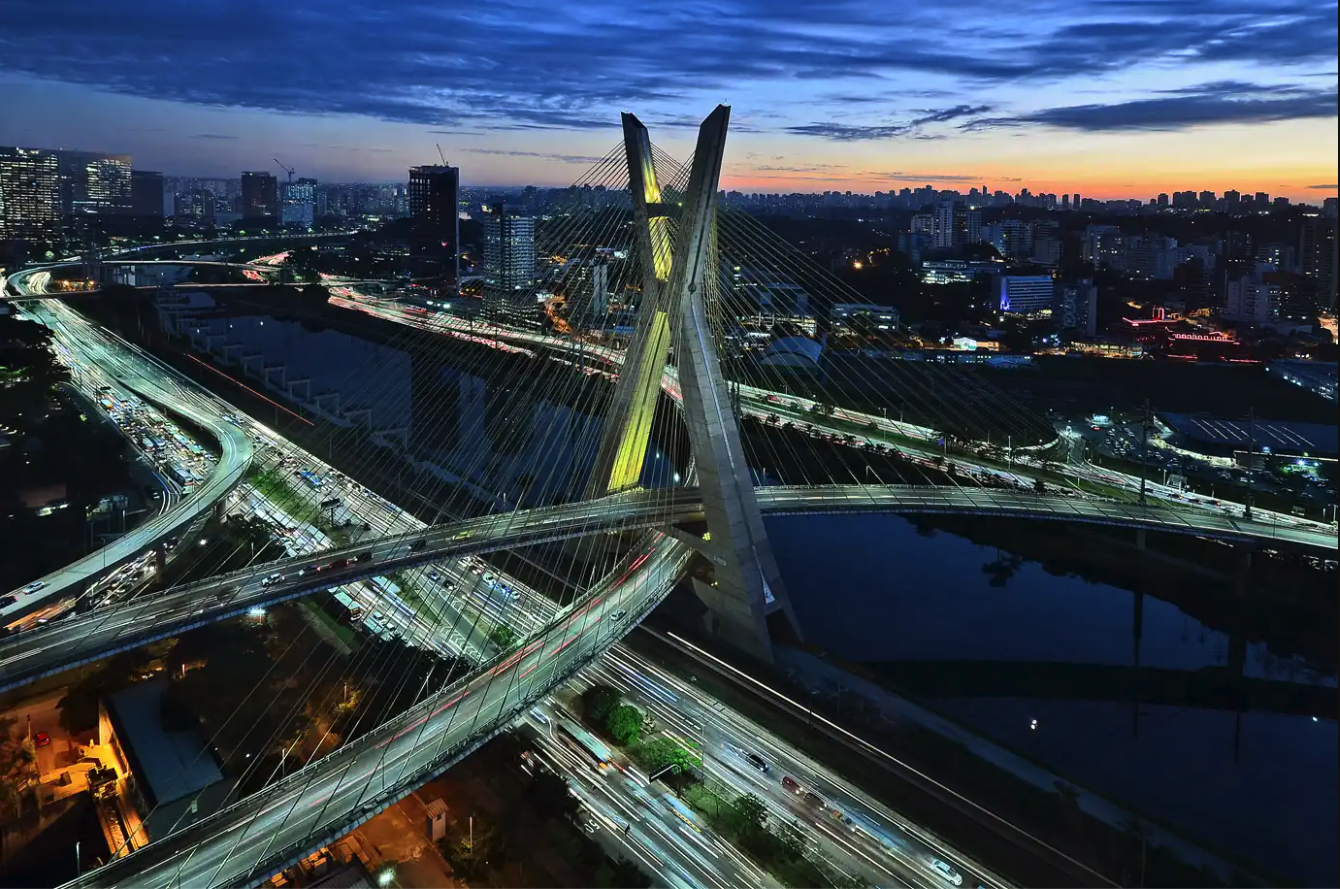

## Objective

To determine the factors that worsen the traffic slowness in São Paulo.

## Import Dataset

In [3]:
import pandas as pd
traffic = pd.read_csv('traffic_sao_paulo.csv', sep=';')
traffic.head()
traffic.info()
traffic.tail()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 135 entries, 0 to 134
Data columns (total 18 columns):
 #   Column                                 Non-Null Count  Dtype 
---  ------                                 --------------  ----- 
 0   Hour (Coded)                           135 non-null    int64 
 1   Immobilized bus                        135 non-null    int64 
 2   Broken Truck                           135 non-null    int64 
 3   Vehicle excess                         135 non-null    int64 
 4   Accident victim                        135 non-null    int64 
 5   Running over                           135 non-null    int64 
 6   Fire vehicles                          135 non-null    int64 
 7   Occurrence involving freight           135 non-null    int64 
 8   Incident involving dangerous freight   135 non-null    int64 
 9   Lack of electricity                    135 non-null    int64 
 10  Fire                                   135 non-null    int64 
 11  Point of flooding  

,Hour (Coded),Immobilized bus,Broken Truck,Vehicle excess,Accident victim,Running over,Fire vehicles,Occurrence involving freight,Incident involving dangerous freight,Lack of electricity,Fire,Point of flooding,Manifestations,Defect in the network of trolleybuses,Tree on the road,Semaphore off,Intermittent Semaphore,Slowness in traffic (%)
130,23,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,"17,8"
131,24,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0,"18,1"
132,25,1,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0,"17,7"
133,26,0,4,0,0,0,0,0,0,0,0,0,1,0,0,1,0,"17,4"
134,27,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,"12,1"


Each row describes the following:

* The time of registering the data: the Hour (Coded) column.
* The number of incidents that happened in São Paulo at the time of registering the data: 
   `Immobilized bus`, `Broken Truck`, `Vehicle excess`, `Fire vehicles`, etc.
* The traffic slowness at the time of registering the data: 'Slowness in traffic (%)'.
* The data was registered from 7:00 to 20:00 every 30 minutes. The `Hour (Coded)` column has values from `1` to `27`:

    * `1` corresponds to 7:00.
    * `2` corresponds to 7:30.
    * `3` corresponds to 8:00.
    ...
    * `26` corresponds to 19:30.
    * `27` corresponds to 20:00.

## Exploring the data

Let's explore  and clean the Slowness in traffic (%) variable

In [4]:
traffic['Slowness in traffic (%)'] = traffic['Slowness in traffic (%)'].str.replace(',', '.')
traffic['Slowness in traffic (%)'] = traffic['Slowness in traffic (%)'].astype(float)

In [5]:
traffic['Slowness in traffic (%)'].describe()

count    135.000000
mean      10.051852
std        4.363243
min        3.400000
25%        7.400000
50%        9.000000
75%       11.850000
max       23.400000
Name: Slowness in traffic (%), dtype: float64

The traffic slowness ranges from 3.4% to 23.4%, with an average of 10.1%. If we order all the values of Slowness in traffic (%) column in ascending order, we see that 25% of the values are under 7.4%, 50% are under 9.0%, and 75% are under 11.9%.

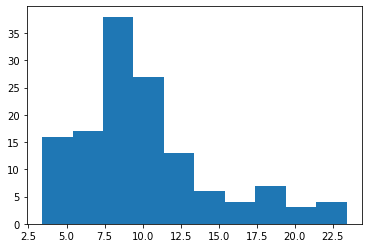

In [6]:
import matplotlib.pyplot as plt

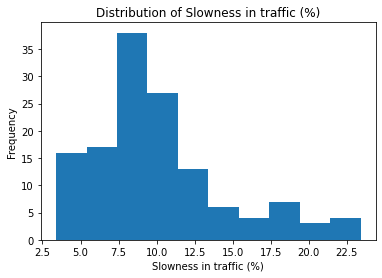

In [9]:
traffic['Slowness in traffic (%)'].plot.hist()
plt.xlabel('Slowness in traffic (%)')
plt.title('Distribution of Slowness in traffic (%)')
plt.show()

The distribution of Slowness in traffic (%) is right skewed. Most values are under 15.0%

## Frequency Incidents

In [10]:
traffic['Broken Truck'].sum()

118

There were 118 borken trucks incidents.

Let's calculate the sums for all the incident columns to compare them. 

In [11]:
# First isolating the incident columns by dropping the columns 'Hour (Coded)' and 'Slowness in traffic (%)').
incidents = traffic.drop(['Hour (Coded)', 'Slowness in traffic (%)'],
                        axis=1)
incidents.sum()

Immobilized bus                           46
Broken Truck                             118
Vehicle excess                             4
Accident victim                           57
Running over                              16
Fire vehicles                              1
Occurrence involving freight               1
Incident involving dangerous freight       1
Lack of electricity                       16
Fire                                       1
Point of flooding                         16
Manifestations                             7
Defect in the network of trolleybuses     31
Tree on the road                           6
Semaphore off                             17
Intermittent Semaphore                     2
dtype: int64

In [12]:
type(incidents.sum())

pandas.core.series.Series

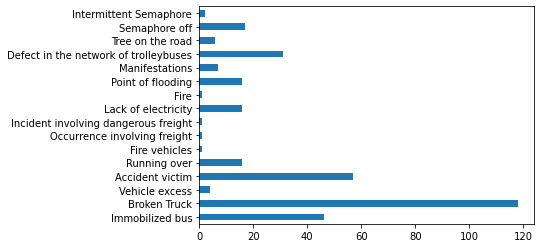

In [14]:
incidents.sum().plot.barh()
plt.show()
plt.size (16,12)

With the barh plot we can see that the most frequent incident type is broken trucks. On the other hand, Lack of electricity and flooding are less frequent than broken trucks

## Correlations with Traffic Slowness

Correlation values will deterpime an accurate picture about each incident type and its relationship with traffic slowness. 

In [15]:
traffic.corr()['Slowness in traffic (%)']

Hour (Coded)                             0.729962
Immobilized bus                          0.101143
Broken Truck                             0.131998
Vehicle excess                          -0.045297
Accident victim                          0.121730
Running over                            -0.001133
Fire vehicles                            0.134103
Occurrence involving freight             0.026791
Incident involving dangerous freight     0.000957
Lack of electricity                      0.436569
Fire                                    -0.046737
Point of flooding                        0.420016
Manifestations                           0.066377
Defect in the network of trolleybuses   -0.147035
Tree on the road                        -0.098489
Semaphore off                            0.347242
Intermittent Semaphore                  -0.119942
Slowness in traffic (%)                  1.000000
Name: Slowness in traffic (%), dtype: float64

Eliminating Hour (Coded) column which doesn't describe an incident type, Slowness in traffic (%) correlates most strongly with the following:

* Lack of electricity: +0.44
* Point of flooding: +0.42
* Semaphore off: +0.34

### Slowness in traffic (%) vs Lack of electricity

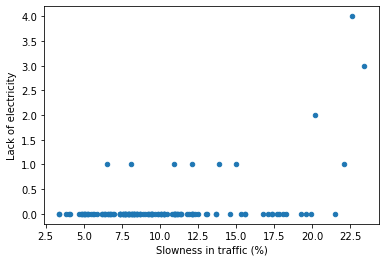

In [17]:
traffic.plot.scatter(x='Slowness in traffic (%)',
                     y='Lack of electricity')
plt.show()

### Slowness in traffic (%) vs Point of flooding

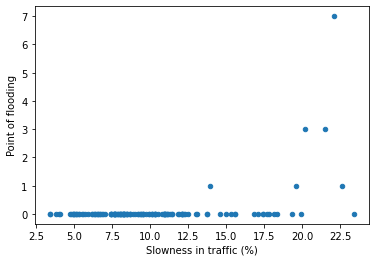

In [18]:
traffic.plot.scatter(x='Slowness in traffic (%)',
                     y='Point of flooding')
plt.show()

### Slowness in traffic (%) vs Semaphore off

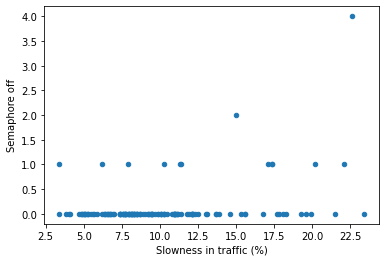

In [19]:
traffic.plot.scatter(x='Slowness in traffic (%)',
                     y='Semaphore off')
plt.show()

## Traffic Slowness Over 20%

In [20]:
slowness_20_or_more = traffic[traffic['Slowness in traffic (%)'] >= 20]
slowness_20_or_more = slowness_20_or_more.drop(['Slowness in traffic (%)',
                                     'Hour (Coded)'], axis=1)

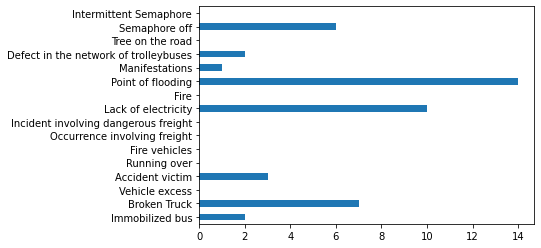

In [21]:
incident_frequencies = slowness_20_or_more.sum()
incident_frequencies.plot.barh()
plt.show()

Lack of electricity and flooding are probably two factors that are causing significant traffic problems. Nonfunctional semaphores also affect traffic, but they are probably a result of lack of electricity.

## Changes in traffic slowness

We will look at the interval from 7:00 to 20:00 

In [22]:
#isolate the data for each day — from Monday to Friday.
days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
traffic_per_day = {}
for i, day in zip(range(0, 135, 27), days):
    each_day_traffic = traffic[i:i+27]
    traffic_per_day[day] = each_day_traffic

In [34]:
print(traffic.index, traffic[0:27])

RangeIndex(start=0, stop=135, step=1)     Hour (Coded)  Immobilized bus  Broken Truck  Vehicle excess  \
0              1                0             0               0   
1              2                0             0               0   
2              3                0             0               0   
3              4                0             0               0   
4              5                0             0               0   
5              6                0             0               0   
6              7                0             0               0   
7              8                0             0               0   
8              9                0             0               0   
9             10                0             0               0   
10            11                0             0               0   
11            12                0             1               0   
12            13                0             0               0   
13            14        

### Slowness in traffic (%) vs Hour (Coded)

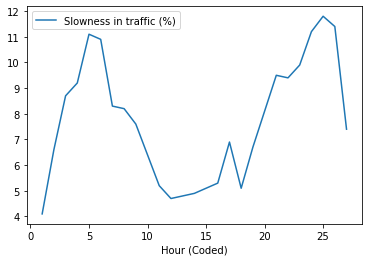

In [23]:
traffic_per_day['Monday'].plot.line(x='Hour (Coded)',
                                    y='Slowness in traffic (%)')
plt.show()

### Changes during each day of the week

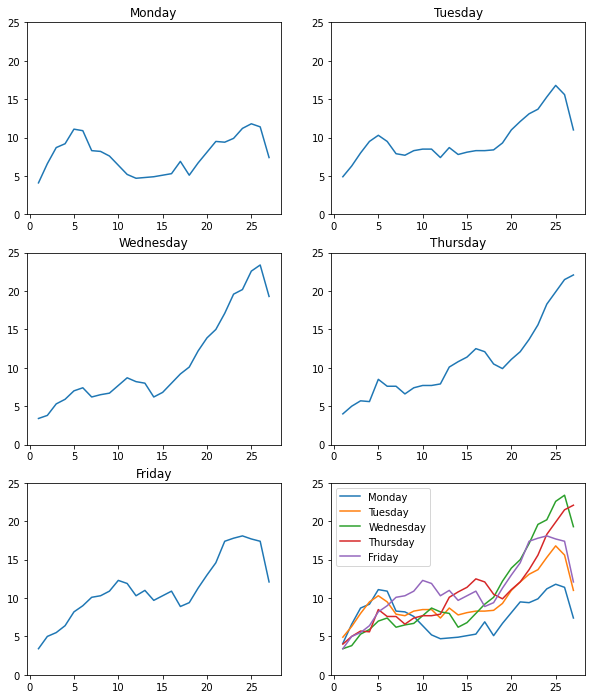

In [41]:
for i, day in zip(range(0, 135, 27), days):
    each_day_traffic = traffic[i:i+27]
    traffic_per_day[day] = each_day_traffic
    
plt.figure(figsize=(10,12))

for i, day in zip(range(1,6), days):
    plt.subplot(3, 2, i)
    plt.plot(traffic_per_day[day]['Hour (Coded)'],
        traffic_per_day[day]['Slowness in traffic (%)'])
    plt.title(day)
    plt.ylim([0,25])
plt.subplot(3, 2, 6)

for day in days:
    plt.plot(traffic_per_day[day]['Hour (Coded)'],
             traffic_per_day[day]['Slowness in traffic (%)'],
             label=day)
    plt.ylim([0,25])

plt.legend()
plt.show()
